# 05 Stochastic processes: describe the dice, not the roll

*Teaching material. Not for clinical use.*

Five prospective studies at civilian centres followed 4,064 haemorrhaging patients after they were admitted to hospital (E-85). Take those who died from haemorrhage, line them up by how long after admission each died, and pick the one in the middle.

**Before reading on, guess.** How long after admission did the middle one die?

- Within 15 minutes
- About 2 hours
- About 12 hours
- A day or more

Write the guess down. It is not marked, and the answer comes in the diagnosis section below.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline
from inference_labs.lenses import stochastic as sto

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID, PALE, GREY = "#7f2704", "#d9d9d9", "#08306b", "#6baed6", "#969696"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)

## The idea, before any medicine

Put a pan of popcorn on the heat. Nobody can say which kernel will pop next, or when. Yet anyone who has made popcorn can say roughly how many will have popped after two minutes, and that the popping starts slowly, comes in a rush and then tails off to a few stragglers. One kernel is unpredictable; the pan is not. And the chance that a given kernel pops in the next ten seconds is not fixed: it depends on how long the pan has been on.

**Plain.** Some things cannot be predicted one at a time but are very predictable in bulk. A stochastic model does not say what will happen to one casualty. It describes the dice: the chance of moving from one state to another in the next interval, and how that chance changes with the clock. The simplest description keeps the chance the same every hour. That is a claim about the process, and it can be wrong: if the danger is greatest early and then fades, a fixed chance misplaces it.

**Developer.** A chain is a set of states and, for each interval, the chance of moving between them. Stepping it forward is a loop:

```python
for hour in range(hours):
    for life in lives:
        if life.state == "bleeding":
            life.state = draw(transition[life.state], hour)    # a fixed chain ignores the hour
```

With a hazard, the chance that a casualty alive now dies by a later time is a subtraction and a division: `q * (F(then) - F(now)) / (1 - q * F(now))`, where `q` is the chance of a bleeding death at all and `F` the share of those deaths that have happened by a given time. Dividing by the share still alive is what makes it a chance for a casualty who is alive now. The cost is one look-up per casualty.

**Technical.** Let $T$ be the time from injury to death from bleeding, with hazard $h(t)$ among those still alive and survival $S(t)=\exp\left(-\int_0^t h(u)\,du\right)$. For a casualty alive at $t_1$, $P(T \le t_2 \mid T > t_1) = \{S(t_1) - S(t_2)\}/S(t_1)$. A fixed-rate chain gives the casualties still bleeding a constant chance of leaving that state each hour, so their time to leave is exponential and memoryless: $P(T > t + s \mid T > t) = P(T > s)$. As a chain over discrete intervals with transition matrix $P$, the distribution after $k$ steps is $\pi_0 P^k$; a time-varying chain uses a different $P_k$ at each step. The generator's hazard is log-quadratic, $\log h(t) = a + bt + ct^2$, passed through E-85's three hourly rates: about 4.6% at 1 hour, about 1% at 6 hours and under 0.1% by 9 hours, the last taken as 0.1%. Those rates were measured from hospital admission; the generator runs them from injury, an assumption, and so does everything below.

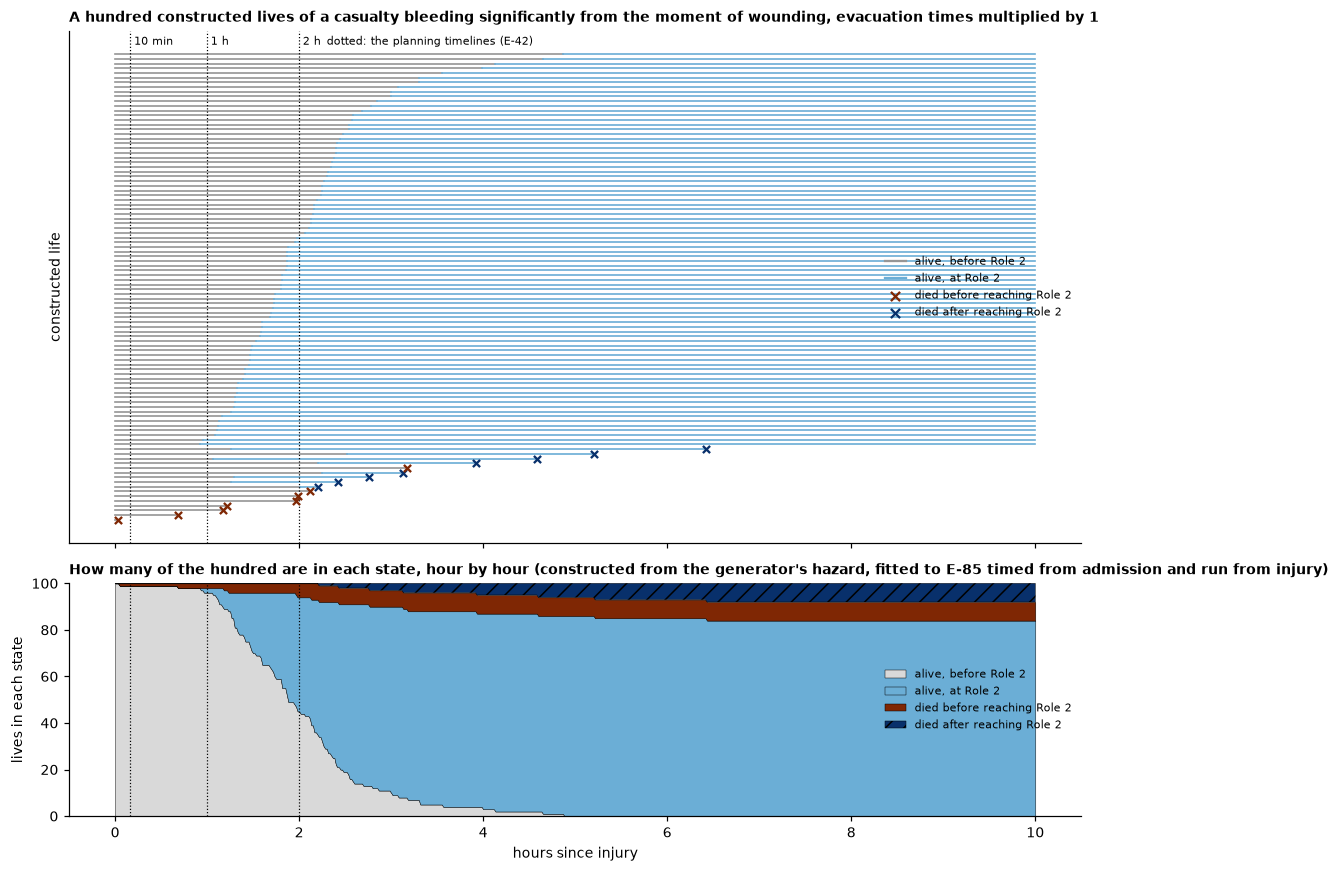

Of 100 constructed lives, by 10 hours: 8 died before reaching Role 2, 8 died after reaching it, 84 alive


In [2]:
# Central figure: many lives. The control: change it and run the cell again.
EVACUATION = 1.0     # 1 keeps the generator's assumed times to pre-hospital care and on to Role 2; 0.5 halves both

lives = sto.lives(evacuation=EVACUATION)
grid = np.linspace(0, 10, 601)
counts = sto.state_counts(lives, grid)
order = lives.assign(key=lives["t_death_h"].fillna(99)).sort_values(["key", "t_role2_h"]).index

fig, (ax, bx) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for y, i in enumerate(order):
    death, arrive = lives.at[i, "t_death_h"], lives.at[i, "t_role2_h"]
    end = grid[-1] if np.isnan(death) else death
    ax.plot([0, min(arrive, end)], [y, y], color=GREY, linewidth=1.1)
    if arrive < end:
        ax.plot([arrive, end], [y, y], color=PALE, linewidth=1.1)
    if not np.isnan(death):
        ax.scatter(death, y, marker="x", s=22, color=DARK if death < arrive else MID, zorder=3)
for minutes, label in zip(sto.TIMELINES_MIN, ("10 min", "1 h", "2 h")):
    for axis in (ax, bx):
        axis.axvline(minutes / 60, color="black", linestyle=":", linewidth=0.8)
    ax.text(minutes / 60 + 0.04, len(lives) + 1, label, fontsize=7)
ax.text(2.3, len(lives) + 1, "dotted: the planning timelines (E-42)", fontsize=7)
ax.set_ylabel("constructed life")
ax.set_yticks([])
ax.plot([], [], color=GREY, label="alive, before Role 2")
ax.plot([], [], color=PALE, label="alive, at Role 2")
ax.scatter([], [], marker="x", color=DARK, label="died before reaching Role 2")
ax.scatter([], [], marker="x", color=MID, label="died after reaching Role 2")
ax.legend(fontsize=7, frameon=False, loc="center right")
ax.set_title(f"A hundred constructed lives of a casualty bleeding significantly from the moment of wounding, evacuation "
             f"times multiplied by {EVACUATION:g}", loc="left", fontsize=9)
colours = [LIGHT, PALE, DARK, MID]
layers = bx.stackplot(grid, counts.T.to_numpy(), colors=colours, labels=list(counts.columns), edgecolor="black",
                      linewidth=0.3)
layers[3].set_hatch("//")
bx.set_ylim(0, len(lives))
bx.set_xlabel("hours since injury")
bx.set_ylabel("lives in each state")
bx.legend(fontsize=7, frameon=False, loc="center right")
bx.set_title("How many of the hundred are in each state, hour by hour (constructed from the generator's hazard, fitted "
             "to E-85 timed from admission and run from injury)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
final = counts.iloc[-1]
print(f"Of {len(lives)} constructed lives, by {grid[-1]:g} hours: {final['died before reaching Role 2']} died before "
      f"reaching Role 2, {final['died after reaching Role 2']} died after reaching it, "
      f"{final['alive, at Role 2'] + final['alive, before Role 2']} alive")

Every one of the hundred lives starts in the same state: a casualty bleeding significantly at the moment of wounding. Each dies from bleeding with the generator's chance for such a casualty, on average over site and severity, at a time drawn from its hazard, and reaches Role 2 at a time drawn from the generator's assumed times to pre-hospital care and on to Role 2. The generator holds one death time for each casualty and no repeated observations, so these lives are **constructed** from its hazard: they show what the description implies, not what any casualty did. No line can be foretold from the others, but the counts beneath change smoothly, and nothing happens at the hour: the dotted lines are the planning timelines of 10 minutes, 1 hour and 2 hours (E-42), and deaths fall on both sides of each.

Change `EVACUATION` to 0.5 and run the cell again. The same hundred lives die at the same times; only their arrival at Role 2 comes sooner, so deaths move from before reaching Role 2 to after it. In this construction reaching Role 2 saves no one: a life's time of death is drawn before, and apart from, its time of arrival. The cell below repeats the comparison on 20 sets of 10,000 constructed lives.

The golden hour study is the field version of the question (E-81). Among 21,089 US casualties in Afghanistan from 2001 to 2014, a policy in 2009 set a sixty-minute limit for evacuation. Among the 4,542 with detailed data, median transport time was 90 minutes before and 43 after. Killed in action was 16.0% (386 of 2,411) before and 9.9% (964 of 9,755) after; died of wounds was 4.1% before and 4.3% after (P=.71). Its limit for this lens: only 37.3% of casualties had matched flight and facility data, so transport time, the quantity this lens is about, was matched for little more than a third of the cohort. The authors list historical controls, a post hoc analysis of non-randomised data, survival bias in their transfusion analysis and several factors changing at once, so that only descriptive interpretation was viable. The fall in killed in action is therefore not attributed here to the sixty-minute limit; lens 07 takes the question up. The construction can move deaths from one state to the other; it cannot say why the field figures moved as they did.

In [3]:
spread = sto.evacuation_spread()
means = spread.mean()
print(f"Deaths from bleeding per 1,000 constructed lives, mean over {len(spread)} sets of {sto.MANY_LIVES:,} "
      f"(constructed; reaching Role 2 saves no one here):")
print(f"  before reaching Role 2: {means['before Role 2, as drawn']:.1f} at the generator's evacuation times, "
      f"{means['before Role 2, faster']:.1f} with both times halved; "
      f"{sto.spread_words(spread['before Role 2, faster'] - spread['before Role 2, as drawn'], 1, ' per 1,000')}")
print(f"  after reaching Role 2:  {means['after reaching Role 2, as drawn']:.1f} and "
      f"{means['after reaching Role 2, faster']:.1f}; "
      f"{sto.spread_words(spread['after reaching Role 2, faster'] - spread['after reaching Role 2, as drawn'], 1, ' per 1,000')}")

Deaths from bleeding per 1,000 constructed lives, mean over 20 sets of 10,000 (constructed; reaching Role 2 saves no one here):
  before reaching Role 2: 83.4 at the generator's evacuation times, 43.1 with both times halved; lower: the difference runs from -43.8 to -37.4 per 1,000 across 20 seeds
  after reaching Role 2:  104.8 and 145.2; higher: the difference runs from +37.4 to +43.8 per 1,000 across 20 seeds


## By hand: ten casualties, a coin and a die

A chain small enough to run on paper. Each casualty is in one of three states: **bleeding**, **stopped** (the bleeding has stopped) or **dead**. Stopped and dead are final. Each hour, for every casualty still bleeding, toss a coin. Heads: nothing changes this hour. Tails: roll a die. A 1 means dead; a 2 or a 3 means the bleeding stops; a 4, 5 or 6 means still bleeding. The dice are constructed for counting, not taken from any source.

The coin and the die for ten casualties over three hours are printed below; each is rolled every hour, and used only while the casualty is still bleeding. Step each casualty forward on paper, hour by hour, and count how many are in each state after each hour. Then run the cells that follow.

In [4]:
table = sto.rolls()
table

,hour 1 coin,hour 1 die,hour 2 coin,hour 2 die,hour 3 coin,hour 3 die
casualty,,,,,,
1,H,3,H,5,T,2
2,H,5,T,3,T,4
3,T,6,H,5,H,6
4,H,4,H,6,T,6
5,T,1,H,2,T,2
6,H,4,T,5,T,3
7,T,6,T,3,T,6
8,H,4,H,5,T,2
9,H,4,T,5,T,6


In [5]:
states = ["bleeding"] * len(table)                 # the same steps in plain Python
counts_by_hour = []
for hour in (1, 2, 3):
    for i, (coin, die) in enumerate(zip(table[f"hour {hour} coin"], table[f"hour {hour} die"])):
        if states[i] == "bleeding" and coin == "T":
            states[i] = "dead" if die == 1 else "stopped" if die in (2, 3) else "bleeding"
    counts_by_hour.append({s: states.count(s) for s in sto.CHAIN_STATES})
hand = pd.DataFrame(counts_by_hour, index=["after hour 1", "after hour 2", "after hour 3"])
library = sto.run_chain(table)
assert library["after hour 3"].tolist() == states                   # the library agrees with the hand count
assert all(library[h].value_counts().reindex(sto.CHAIN_STATES, fill_value=0).tolist() == hand.loc[h].tolist()
           for h in hand.index)
hand

,bleeding,stopped,dead
after hour 1,9,0,1
after hour 2,7,2,1
after hour 3,4,5,1


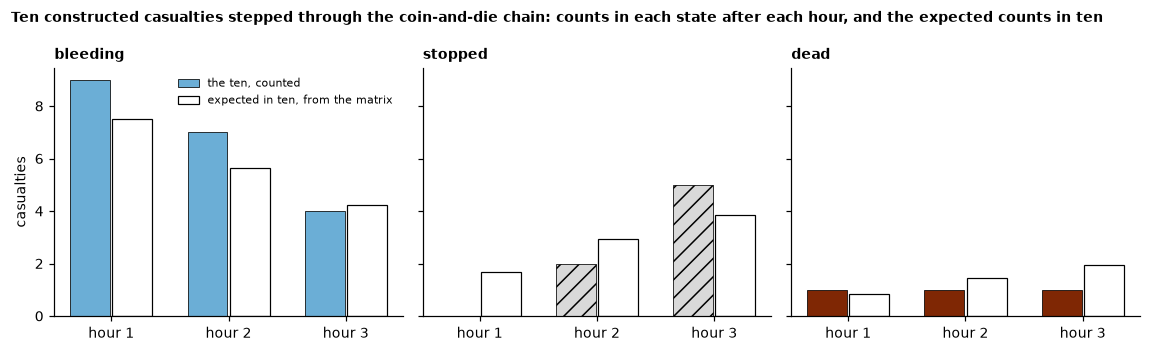

,bleeding,stopped,dead
start,100.0,0.0,0.0
after hour 1,75.0,16.7,8.3
after hour 2,56.2,29.2,14.6
after hour 3,42.2,38.5,19.3


In [6]:
expected = sto.expected_shares()
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
for ax, state, colour, hatch in zip(axes, sto.CHAIN_STATES, (PALE, LIGHT, DARK), ("", "//", "")):
    hours = np.arange(1, 4)
    ax.bar(hours - 0.18, hand[state], 0.34, color=colour, hatch=hatch, edgecolor="black", linewidth=0.5,
           label="the ten, counted")
    ax.bar(hours + 0.18, 10 * expected.loc[hand.index, state], 0.34, color="white", edgecolor="black",
           linewidth=0.8, label="expected in ten, from the matrix")
    ax.set_xticks(hours, ["hour 1", "hour 2", "hour 3"])
    ax.set_title(state, loc="left", fontsize=9)
axes[0].set_ylabel("casualties")
axes[0].legend(fontsize=7, frameon=False)
fig.suptitle("Ten constructed casualties stepped through the coin-and-die chain: counts in each state after each hour, "
             "and the expected counts in ten", x=0.01, ha="left", fontweight="bold", fontsize=9)
plt.tight_layout()
plt.show()
(100 * expected).round(1)

Written as a matrix, with a row for the state now and a column for the state an hour later, in the order bleeding, stopped, dead:

$$P = \begin{pmatrix} 3/4 & 1/6 & 1/12 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{pmatrix}$$

The top row is the coin and the die: three chances in four of no change (heads, or tails and a 4, 5 or 6), one in six of the bleeding stopping and one in twelve of death. Starting with everyone bleeding, $\pi_0 = (1, 0, 0)$, the expected shares after $k$ hours are $\pi_0 P^k$, printed above as percentages: after three hours 42.2% still bleeding, 38.5% stopped and 19.3% dead. Ten casualties scatter around that; ten thousand would sit close to it. This chain is memoryless: a casualty still bleeding after two hours faces the same coin and die as at the start. A time-varying chain changes the top row with the hour.

## Diagnosis: deterioration from point of injury to Role 2

**The answer to the hook.** Among the 4,064 haemorrhaging patients of E-85's five prospective studies at civilian centres, the median time from hospital admission to death from haemorrhage was 2.0 to 2.6 hours, and about 85% of those deaths came within 6 hours. The hourly death rate was about 4.6% at 1 hour, about 1% at 6 hours and under 0.1% by 9 hours. The risk is front-loaded.

All of these figures are measured from hospital admission. The casualty here is followed from the moment of wounding, and the generator runs E-85's hazard from injury: that is an assumption, and every figure below that uses E-85 carries it.

Two descriptions of the dice, each checked against E-85:

- **A fixed-rate chain.** Whether a casualty bleeding significantly dies is as in the generator, but one who will die does so at a fixed hourly rate, ln 2 over the median time to death, so that its median matches the time-varying hazard's. This is the generator's constant-hazard option, written as a chain.
- **The time-varying hazard.** The generator's own, log-quadratic in time since injury through E-85's three hourly rates.

The fixed-rate chain is fitted to the median and the time-varying hazard to the three rates; neither is fitted to the share of deaths within 6 hours, so that is a check on both, and the median is a check on the time-varying hazard. E-25 is set beside them: in the trials pooled by E-24, 884 of 1,408 bleeding deaths (63%) came within 12 hours of onset; half of those patients were obstetric, and time-to-death data existed only for the obstetric trial (E-26).

In [7]:
check = sto.e85_check()
shown = check.copy()
for col in ("fixed-rate chain", "time-varying hazard"):
    shown[col] = [f"{v:.2f} hours" if "median" in name else f"{100 * v:.2f}%" if "rate" in name else f"{100 * v:.1f}%"
                  for name, v in check[col].items()]
print(f"Chance of a bleeding death, casualties bleeding significantly, on average over site and severity: "
      f"{sto.death_chance():.1%}")
print(f"Fixed-rate chain: a casualty who will die does so at {sto.constant_rate():.3f} an hour, ln 2 over the median of "
      f"{sto.median_death_h():.2f} hours")
print("Computed from the hazard (E-85 timed from admission, run here from injury):")
shown

Chance of a bleeding death, casualties bleeding significantly, on average over site and severity: 18.8%
Fixed-rate chain: a casualty who will die does so at 0.314 an hour, ln 2 over the median of 2.21 hours
Computed from the hazard (E-85 timed from admission, run here from injury):


,published,source,fixed-rate chain,time-varying hazard
figure,,,,
hourly death rate among those alive at 1 hours,about 4.6%,E-85,4.56%,4.60%
hourly death rate among those alive at 6 hours,about 1%,E-85,1.07%,1.00%
hourly death rate among those alive at 9 hours,under 0.1%,E-85,0.43%,0.10%
"median time to death among bleeding deaths, hours",2.0 to 2.6,E-85,2.21 hours,2.21 hours
share of bleeding deaths within 6 hours,about 85%,E-85,84.8%,94.1%
share of bleeding deaths within 12 hours,"884 of 1,408 (63%), from onset",E-25,97.7%,100.0%


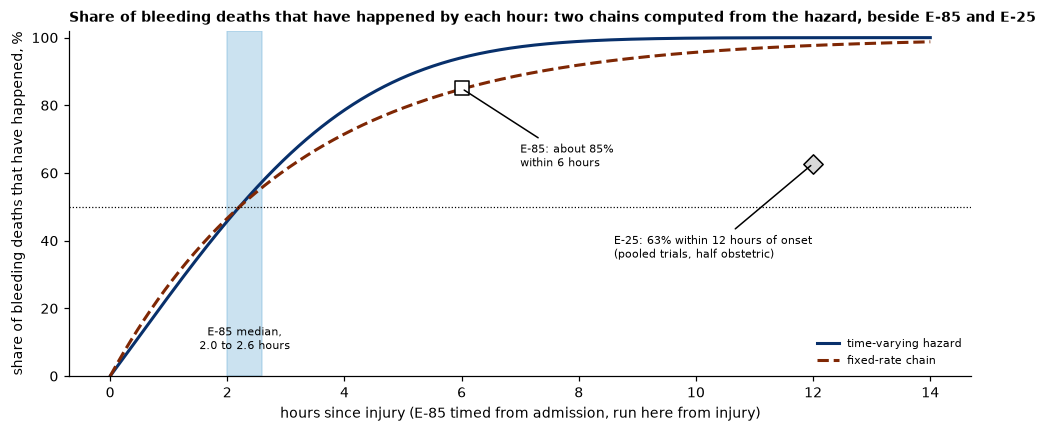

In [8]:
hours = np.linspace(0, 14, 841)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hours, 100 * sto.deaths_by(hours), color=MID, linewidth=2, label="time-varying hazard")
ax.plot(hours, 100 * sto.deaths_by(hours, "constant"), "--", color=DARK, linewidth=2, label="fixed-rate chain")
ax.axvspan(*sto.E85_MEDIAN_H, color=PALE, alpha=0.35)
ax.text(np.mean(sto.E85_MEDIAN_H), 8, "E-85 median,\n2.0 to 2.6 hours", ha="center", fontsize=7)
ax.scatter([6], [100 * sto.E85_WITHIN_6H], s=80, marker="s", color="white", edgecolor="black", zorder=3)
ax.annotate("E-85: about 85%\nwithin 6 hours", (6, 85), xytext=(7, 62), fontsize=7, arrowprops={"arrowstyle": "-"})
ax.scatter([12], [100 * sto.E25_WITHIN_12H / sto.E25_DEATHS], s=80, marker="D", color=LIGHT, edgecolor="black",
           zorder=3)
ax.annotate("E-25: 63% within 12 hours of onset\n(pooled trials, half obstetric)", (12, 62.8), xytext=(8.6, 35),
            fontsize=7, arrowprops={"arrowstyle": "-"})
ax.axhline(50, color="black", linestyle=":", linewidth=0.8)
ax.set_xlabel("hours since injury (E-85 timed from admission, run here from injury)")
ax.set_ylabel("share of bleeding deaths that have happened, %")
ax.set_ylim(0, 102)
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("Share of bleeding deaths that have happened by each hour: two chains computed from the hazard, beside "
             "E-85 and E-25", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

Read against E-85, the two descriptions go wrong in different places. Both hold the median, the fixed-rate chain because it was fitted to it, and the time-varying hazard without being fitted to it. On the share of deaths within 6 hours the fixed-rate chain, at 84.8%, is closer to E-85's about 85% than the time-varying hazard, at 94.1%: the generator's hazard puts more of the deaths early than E-85 reports. On the hourly rates the order reverses: the time-varying hazard passes through all three, by construction, while the fixed-rate chain holds the rate at 9 hours over four times E-85's. Neither description matches every one of E-85's figures. Which matters depends on the question. A rate is what says whether a casualty still alive at 9 hours remains in danger, and that is where the failure section takes the fixed-rate chain apart.

E-25 sits far from both: 63% of bleeding deaths within 12 hours of onset in the pooled trials, against nearly all of them in either chain. The populations differ, half of E-25's patients being obstetric (E-26), and its clock starts at onset, not at admission. A rate fitted to one population is a claim about that population: the generator's hazard is fitted to E-85's patients, timed from admission, and run from injury.

### What each source measures, and from when

E-85 measures deaths after admission: its clock starts when the patient reaches hospital. E-127 measures before it. In a US registry from 2012 to 2014, 42,135 adults with torso injury and a prehospital systolic pressure of 110 or less, after severe head injury and unsurvivable injury were excluded, had a mortality of 7.9%; their median prehospital time was 37 minutes, 28 for penetrating and 40 for blunt injury. Their risk of death rose with prehospital time, most steeply in the first 30 minutes, in those with high-grade torso injury. It is a second, independent source for a front-loaded risk, specific to torso injury and measured before hospital, where E-85 starts after admission. E-127's measure ends at arrival at hospital and E-85's begins there.

The generator uses E-85 alone and runs its clock from injury, an assumption. The figure below shows how far that moves E-85's three points: drawn from injury, as the generator uses them, and drawn from arrival at Role 2 at the generator's median arrival time for its battle casualties, which is where a clock that starts at admission would put them for a casualty arriving then. The second placing is an illustration on the generator's assumed times, not a finding.

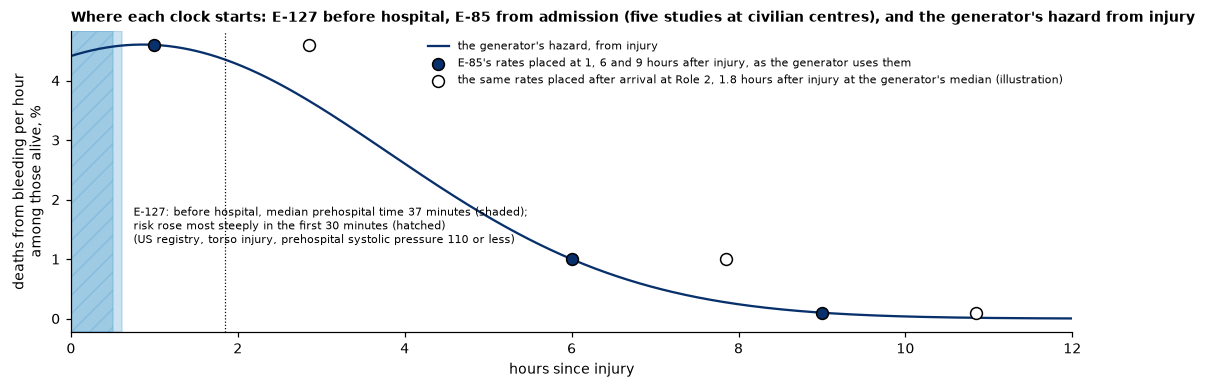

In [9]:
observed, truth = baseline.generator_sample()
battle = (observed["stream"] == "battle").to_numpy()
hours = np.linspace(0, 12, 721)
arrival_h = float(np.median(observed.loc[battle, "t_role2_min"])) / 60
rates = [float(sto.hourly_rate(h)) for h in sto.HOURS]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(0, sto.E127["median_min"] / 60, color=PALE, alpha=0.35)
ax.axvspan(0, 0.5, color=PALE, alpha=0.45, hatch="//")
ax.text(0.75, 1.9, f"E-127: before hospital, median prehospital time {sto.E127['median_min']} minutes (shaded);\nrisk "
        f"rose most steeply in the first 30 minutes (hatched)\n(US registry, torso injury, prehospital systolic "
        f"pressure 110 or less)", fontsize=7, va="top")
ax.plot(hours, 100 * sto.hourly_rate(hours), color=MID, linewidth=1.5,
        label="the generator's hazard, from injury")
ax.scatter(sto.HOURS, [100 * r for r in rates], s=60, marker="o", color=MID, edgecolor="black", zorder=3,
           label="E-85's rates placed at 1, 6 and 9 hours after injury, as the generator uses them")
ax.scatter([arrival_h + h for h in sto.HOURS], [100 * r for r in rates], s=60, marker="o", color="white",
           edgecolor="black", zorder=3,
           label=f"the same rates placed after arrival at Role 2, {arrival_h:.1f} hours after injury at the "
                 f"generator's median (illustration)")
ax.axvline(arrival_h, color="black", linestyle=":", linewidth=0.8)
ax.set_xlim(0, 12)
ax.set_xlabel("hours since injury")
ax.set_ylabel("deaths from bleeding per hour\namong those alive, %")
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_title("Where each clock starts: E-127 before hospital, E-85 from admission (five studies at civilian centres), "
             "and the generator's hazard from injury", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

### On the generator: where the bleeding deaths fall, and the lens's chance

Among the 100,000 synthetic casualties of the military cohort (seed 42), the battle casualties bleeding significantly are followed from injury, using the generator's outcome without tranexamic acid. The first table counts where each one's bleeding death falls: before pre-hospital care, between it and arrival at Role 2, after arrival, or not at all. The generator has no effect of reaching Role 2 on a death from bleeding; of what is done to a casualty, only tranexamic acid changes it (mechanism).

The lens's diagnosis is asked at pre-hospital care, of a casualty alive then: if this casualty is bleeding significantly, what is the chance of dying from bleeding in the next hour? The casualties already dead from bleeding are not there to be asked, so they are left out, and the chance is conditional on being alive at that time. The lens reads only the minutes since injury; it is told who is bleeding, which the generator knows and no medic knows for certain. The figure sets the chance against the share who did die within the hour, in bands of time since injury.

In [10]:
display(sto.where_bleeding_deaths_fall().to_frame())
dx = sto.diagnosis_results()
sp = sto.scorecard_spread()
print(f"Battle casualties bleeding significantly and alive at pre-hospital care: {dx['casualties']:,}; died from bleeding "
      f"within the hour after it: {dx['died in the next hour']:,} ({dx['died in the next hour'] / dx['casualties']:.1%})")
print(f"The lens's chance: mean {dx['mean chance']:.4f}, highest {dx['highest chance']:.4f}; mean chance minus observed "
      f"share {dx['lens']['calibration']:+.4f}, and across {len(sp)} further samples "
      f"{sto.spread_words(sp['lens calibration'], 4)} (mechanism)")

,synthetic battle casualties
bleeding significantly,10834
died before pre-hospital care,482
died between pre-hospital care and Role 2,414
died after reaching Role 2,1103
did not die from bleeding,8835


Battle casualties bleeding significantly and alive at pre-hospital care: 10,352; died from bleeding within the hour after it: 439 (4.2%)
The lens's chance: mean 0.0430, highest 0.0448; mean chance minus observed share +0.0006, and across 20 further samples a tie: no detectable difference (the difference runs from -0.0042 to +0.0053 across 20 seeds) (mechanism)


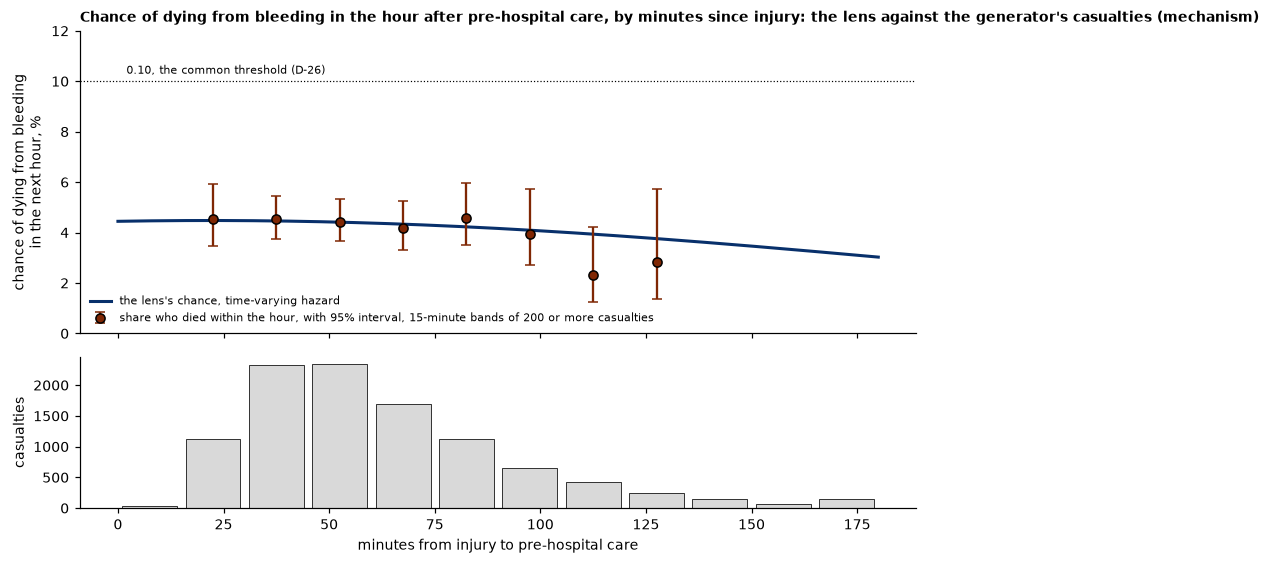

In [11]:
from inference_labs.lenses.frequentist import wilson

care = dx["minutes"]
edges = np.arange(0, 181, 15)
band = np.digitize(care, edges[1:-1])
size = np.array([(band == k).sum() for k in range(len(edges) - 1)])
died = np.array([dx["target"][band == k].sum() for k in range(len(edges) - 1)])
mid = (edges[:-1] + edges[1:]) / 2
keep = size >= 200
interval = np.array([wilson(int(k), int(n)) for k, n in zip(died[keep], size[keep])])
line = np.arange(0, 181)
fig, (ax, bx) = plt.subplots(2, 1, figsize=(8.5, 5.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax.plot(line, 100 * sto.next_hour(line), color=MID, linewidth=2, label="the lens's chance, time-varying hazard")
ax.errorbar(mid[keep], 100 * interval[:, 0], yerr=[100 * (interval[:, 0] - interval[:, 1]),
            100 * (interval[:, 2] - interval[:, 0])], fmt="o", color=DARK, markeredgecolor="black", capsize=3,
            label="share who died within the hour, with 95% interval, 15-minute bands of 200 or more casualties")
ax.axhline(100 * 0.10, color="black", linestyle=":", linewidth=0.8)
ax.text(2, 10.3, "0.10, the common threshold (D-26)", fontsize=7)
ax.set_ylim(0, 12)
ax.set_ylabel("chance of dying from bleeding\nin the next hour, %")
ax.legend(fontsize=7, frameon=False, loc="lower left")
ax.set_title("Chance of dying from bleeding in the hour after pre-hospital care, by minutes since injury: the lens "
             "against the generator's casualties (mechanism)", loc="left", fontsize=9)
bx.bar(mid, size, 13, color=LIGHT, edgecolor="black", linewidth=0.5)
bx.set_xlabel("minutes from injury to pre-hospital care")
bx.set_ylabel("casualties")
plt.tight_layout()
plt.show()

The chance hardly moves across the times at which casualties reach pre-hospital care: the hazard is near its peak for the first two hours, so a casualty seen at 30 minutes and one seen at 90 face much the same next hour. It matches the share who died because the lens's hazard is the generator's, so that agreement is by construction. No casualty here reaches a chance of 0.10, the common threshold (D-26), so at that threshold the lens flags none. The lens describes the crowd's clock. What decides which bleeding casualty dies in the generator, the site and the severity of the bleeding, is not in the clock (mechanism).

## Treatment: the melting hour

This section is about a treatment, and its results are kept apart from the diagnosis results above.

CRASH-2 randomised 20,211 trauma patients with significant haemorrhage within 8 hours of injury, in 274 hospitals in 40 countries, to tranexamic acid or placebo (E-19). It is a civilian trial. Its analysis by time to treatment found, for death from bleeding (E-22):

| time to treatment | tranexamic acid | placebo | relative risk (95% interval) |
|---|---|---|---|
| up to 1 hour | 5.3% | 7.7% | 0.68 (0.57 to 0.82) |
| 1 to 3 hours | 4.8% | 6.1% | 0.79 (0.64 to 0.97) |
| over 3 hours | 4.4% | 3.1% | 1.44 (1.12 to 1.84) |

After 3 hours there were more deaths from bleeding with the drug than without it: harm, not benefit. The analysis was exploratory, not a pre-specified primary result (E-23), and the trial civilian, so applying it to a battle casualty is an assumption. A pooled analysis of 40,138 patients, from CRASH-2 (20,127, trauma) and WOMAN (20,011, postpartum haemorrhage), put the odds ratio for survival with immediate treatment at 1.72 (1.42 to 2.10), and found that the benefit fell by about 10% for each 15 minutes of delay, with none after about 3 hours (E-24). Half of those patients were obstetric, trauma onset times are often unwitnessed, and the estimate was adjusted only for age and systolic pressure (E-26). The 10% per 15 minutes is not a trauma-only figure.

The lens joins them as a function of time. Its relative reduction in death from bleeding falls in a straight line to none at 3 hours, where E-24 puts the end of the benefit. The straight line is an assumption: it falls by 8.3% of the reduction at zero delay for each 15 minutes, against E-24's about 10%. Its height is set so that its average over the first hour matches E-22's first band, using the generator's spread of delays within that hour, also an assumption. E-22's first band is carried as 4,000 draws from a log-normal fitted to its interval, so the line carries that band's uncertainty; after 3 hours the lens uses E-22's band over 3 hours, also as draws. The second band is not used to set the line, so it is a check. The generator's own relative risk in each band, on its battle casualties bleeding significantly and alive at pre-hospital care, is shown beside them; the generator was built to reproduce E-22's bands.

In [12]:
bands = sto.band_check()
bands.round(3)

,E-22,E-22 interval,"lens, mean of draws",lens interval,generator,casualties
band,,,,,,
up to 1 hour,0.68,0.57 to 0.82,0.682,0.57 to 0.81,0.683,5841
1 to 3 hours,0.79,0.64 to 0.97,0.791,0.72 to 0.88,0.791,4417
over 3 hours,1.44,1.12 to 1.84,1.453,1.12 to 1.84,1.439,94


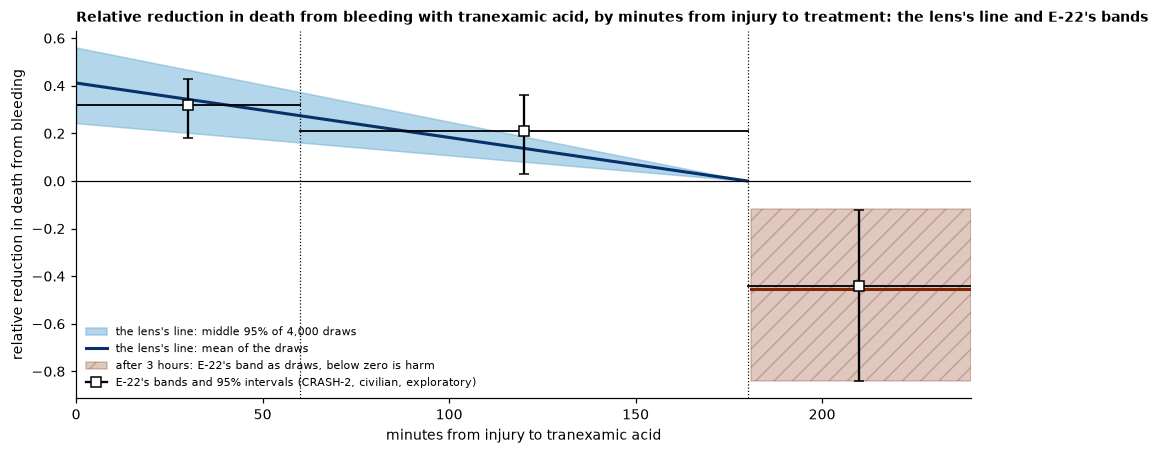

Share of the reduction at zero delay left on the line: 83% at 30 minutes, 67% at 60, 33% at 120, none at 180; a fall of 8.3% of it for each 15 minutes, against E-24's about 10%


In [13]:
curve = sto.decline_curve(tuple(range(0, 181, 2)))
late = sto.decline_curve((181, 240))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(curve.index, curve["lo"], curve["hi"], color=PALE, alpha=0.5, label="the lens's line: middle 95% of 4,000 draws")
ax.plot(curve.index, curve["mean"], color=MID, linewidth=2, label="the lens's line: mean of the draws")
ax.fill_between(late.index, late["lo"], late["hi"], color=DARK, alpha=0.25, hatch="//",
                label="after 3 hours: E-22's band as draws, below zero is harm")
ax.plot(late.index, late["mean"], color=DARK, linewidth=2)
for name, lo, hi, (rr, rlo, rhi), _ in sto.E22_BANDS:
    hi = min(hi, 240)
    ax.plot([lo, hi], [1 - rr, 1 - rr], color="black", linewidth=1.2)
    ax.errorbar((lo + hi) / 2, 1 - rr, yerr=[[(1 - rr) - (1 - rhi)], [(1 - rlo) - (1 - rr)]], fmt="s", color="white",
                markeredgecolor="black", ecolor="black", capsize=3)
ax.plot([], [], color="black", marker="s", markerfacecolor="white", label="E-22's bands and 95% intervals (CRASH-2, civilian, exploratory)")
ax.axhline(0, color="black", linewidth=0.8)
for m in (60, 180):
    ax.axvline(m, color="black", linestyle=":", linewidth=0.8)
ax.set_xlim(0, 240)
ax.set_xlabel("minutes from injury to tranexamic acid")
ax.set_ylabel("relative reduction in death from bleeding")
ax.legend(fontsize=7, frameon=False, loc="lower left")
ax.set_title("Relative reduction in death from bleeding with tranexamic acid, by minutes from injury to treatment: "
             "the lens's line and E-22's bands", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Share of the reduction at zero delay left on the line: {sto.benefit_left(30):.0%} at 30 minutes, "
      f"{sto.benefit_left(60):.0%} at 60, {sto.benefit_left(120):.0%} at 120, none at 180; a fall of "
      f"{sto.LINE_DECLINE_PER_15MIN:.1%} of it for each 15 minutes, against E-24's about "
      f"{sto.E24['decline_per_15min']:.0%}")

On the generator, take the battle casualties bleeding significantly and alive at pre-hospital care, when the drug is given. For each, the chance of dying from bleeding after that time without the drug, conditional on being alive then, times the lens's relative reduction at their own delay, gives the expected deaths averted; these are summed and put per 100, with the draws carried through. The same is computed as if every one of them were reached 30 minutes later, by which time some will have died and the rest have less benefit left. The generator's own count, from its outcomes with and without the drug on the same casualties, is the check. All are mechanism, on synthetic casualties, and both the lens's line and the generator were set from E-22's bands, from CRASH-2, a civilian trial, so agreement between them is by construction.

In [14]:
tx = sto.treatment_results()
own, later = tx["own delay"], tx["30 minutes later"]
print(f"{tx['casualties']:,} battle casualties bleeding significantly and alive at pre-hospital care; median delay "
      f"{tx['median delay']:.0f} minutes; {tx['over 3 hours']} reached after 3 hours (mechanism)")
print(f"Expected deaths from bleeding averted per 100, the drug at their own delay: {own.mean():.2f} "
      f"({own.interval()[0]:.2f} to {own.interval()[1]:.2f})")
print(f"Expected deaths averted per 100 with every one reached 30 minutes later: {later.mean():.2f} "
      f"({later.interval()[0]:.2f} to {later.interval()[1]:.2f}); across {len(sp)} further samples, 30 minutes later "
      f"less own delay: {sto.spread_words(sp['averted 30 minutes later, lens'] - sp['averted, lens'], 2, ' per 100')}")
print(f"The generator's own count at their own delay: {tx['generator count']:.2f} per 100; lens less count across "
      f"{len(sp)} further samples: {sto.spread_words(sp['averted, lens'] - sp['averted, generator'], 2, ' per 100')}")

10,352 battle casualties bleeding significantly and alive at pre-hospital care; median delay 55 minutes; 94 reached after 3 hours (mechanism)
Expected deaths from bleeding averted per 100, the drug at their own delay: 4.14 (2.44 to 5.65)
Expected deaths averted per 100 with every one reached 30 minutes later: 2.64 (1.53 to 3.61); across 20 further samples, 30 minutes later less own delay: lower: the difference runs from -1.51 to -1.50 per 100 across 20 seeds
The generator's own count at their own delay: 4.15 per 100; lens less count across 20 further samples: a tie: no detectable difference (the difference runs from -0.42 to +0.40 per 100 across 20 seeds)


### Early against late outcome

RePHILL randomised 432 patients, through four English prehospital critical care services, to red cells and lyophilised plasma or to saline (E-77). Death within 3 hours was 16% against 22%, relative risk 0.75 (0.50 to 1.13); death, one component of its primary outcome, was 43% against 45%, relative risk 0.97 (0.78 to 1.20). Both intervals include no difference. The early gap is the larger. RePHILL tested blood, not tranexamic acid, and its figures are set beside the mechanism below as a pattern, not as evidence about either treatment.

Can the generator show a benefit counted at 3 hours diluted by 30 days? In the generator the drug changes whether a casualty dies from bleeding, not when, every bleeding death falls within its 24-hour horizon, and bleeding is the only cause of death. With nothing added, the relative risk at 30 days is the relative risk of a bleeding death at any time, and the table below shows it a tie with the one at 3 hours. To count at 30 days, later deaths from other causes are constructed: among those who survive their bleeding, a share die later, the same share with and without the drug. The share is an assumption, so it is shown at five values, from none to 40%. The casualties are the battle casualties bleeding significantly and alive at pre-hospital care, given the drug or not at random by the generator within 3 hours of injury, in 20 samples of 400,000 synthetic casualties (mechanism).

,"3 hours: with, %","3 hours: without, %",3 hours: relative risk,"30 days: with, %","30 days: without, %",30 days: relative risk,30-day less 3-hour relative risk
share of survivors dying later (assumed),,,,,,,
0.0,5.667,8.011,0.708,10.787,14.996,0.720,a tie: no detectable difference (the difference runs from -0.02 to +0.06 across 20 seeds)
0.1,5.667,8.011,0.708,19.627,23.444,0.837,higher: the difference runs from +0.09 to +0.19 across 20 seeds
0.2,5.667,8.011,0.708,28.501,32.006,0.891,higher: the difference runs from +0.15 to +0.24 across 20 seeds
0.3,5.667,8.011,0.708,37.468,40.475,0.926,higher: the difference runs from +0.17 to +0.29 across 20 seeds
0.4,5.667,8.011,0.708,46.385,49.004,0.947,higher: the difference runs from +0.20 to +0.30 across 20 seeds


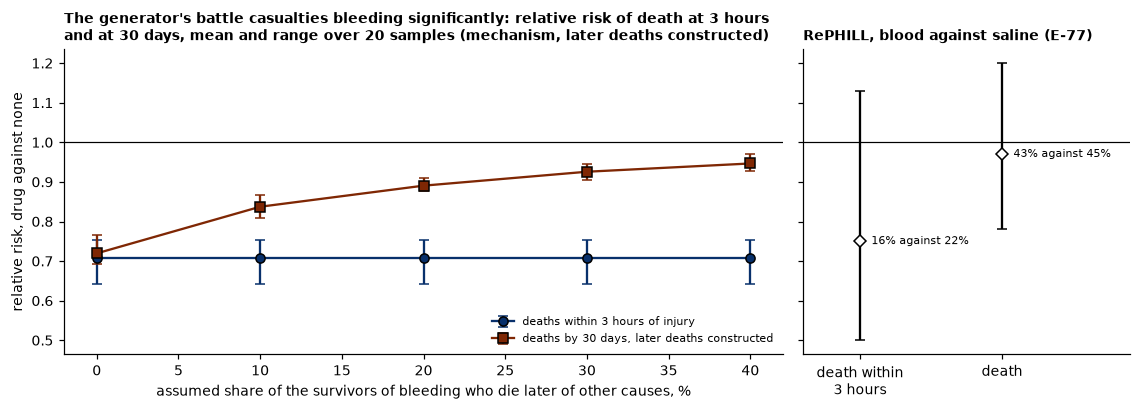

In [15]:
dilution = sto.dilution_summary()
display(dilution.round(3))
table = sto.early_late_spread()
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [2.2, 1]}, sharey=True)
for col, colour, marker, label in (("3 hours relative risk", MID, "o", "deaths within 3 hours of injury"),
                                   ("30 days relative risk", DARK, "s", "deaths by 30 days, later deaths constructed")):
    g = table.groupby("later share")[col]
    x = 100 * np.array(sto.LATER_SHARES)
    ax.errorbar(x, g.mean(), yerr=[g.mean() - g.min(), g.max() - g.mean()], fmt=marker + "-", color=colour,
                markeredgecolor="black", capsize=3, label=label)
ax.axhline(1, color="black", linewidth=0.8)
ax.set_xlabel("assumed share of the survivors of bleeding who die later of other causes, %")
ax.set_ylabel("relative risk, drug against none")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("The generator's battle casualties bleeding significantly: relative risk of death at 3 hours\nand at "
             "30 days, mean and range over 20 samples (mechanism, later deaths constructed)", loc="left", fontsize=9)
for k, (name, (with_, without, (rr, lo, hi))) in enumerate((("within 3 hours", sto.E77["early"]),
                                                             ("death", sto.E77["death"]))):
    bx.errorbar(k, rr, yerr=[[rr - lo], [hi - rr]], fmt="D", color="white", markeredgecolor="black", ecolor="black",
                capsize=3)
    bx.text(k + 0.08, rr, f"{100 * with_:.0f}% against {100 * without:.0f}%", fontsize=7, va="center")
bx.axhline(1, color="black", linewidth=0.8)
bx.set_xticks([0, 1], ["death within\n3 hours", "death"])
bx.set_xlim(-0.4, 1.9)
bx.set_title("RePHILL, blood against saline (E-77)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

With no later deaths the two relative risks are a tie across the 20 samples: on the generator, counting bleeding deaths later does not detectably change the drug's relative effect. Each later death added moves the 30-day relative risk towards one, because deaths the drug does not touch are counted in both arms. At the larger shares the pattern resembles RePHILL's point estimates, an early relative risk well below one and a late one near one, but that resemblance is made by the assumed share, not found.

The absolute gap behaves differently. Counted at 30 days, it includes the bleeding deaths averted after 3 hours as well as before, and it narrows only as later deaths take some of those saved from bleeding; at every share shown, on the means over the 20 samples in the table above, it is at least the 3-hour gap. RePHILL's late gap, 2 points, is smaller than its early gap, 6 points. The construction reproduces the dilution of the relative risk, not the narrowing of the absolute gap.

### Recorded time is rounded

CRASH-2's authors note digit preference in the reported time from injury (E-20); CRASH-2 is a civilian trial. Here every delay in the generator is recorded to the nearest half hour, halves rounded up, and the decline is read again from the recorded times. Rounding every time is a simplification of digit preference. So that chance deaths do not hide the change, the decline is read from each casualty's chance of a bleeding death with and without the drug, which the generator holds and a trial does not: a straight line through one minus their ratio, against delay up to 3 hours, and the relative risk in each of E-22's bands as the sum of chances with the drug over the sum without. The casualties are the battle casualties bleeding significantly and alive at pre-hospital care, in 20 samples of 100,000 (mechanism).

,exact,recorded,recorded less exact
"figure, mean over seeds",,,
reduction at zero delay,0.410,0.408,a tie: no detectable difference (the difference runs from -0.004 to +0.001 across 20 seeds)
"none after, hours",3.000,2.990,a tie: no detectable difference (the difference runs from -0.05 to +0.04 hours across 20 seeds)
"fall per 15 minutes, share",0.083,0.083,a tie: no detectable difference (the difference runs from -0.001 to +0.001 across 20 seeds)
"relative risk, up to 1 hour",0.683,0.696,higher: the difference runs from +0.013 to +0.014 across 20 seeds
"relative risk, 1 to 3 hours",0.790,0.827,higher: the difference runs from +0.034 to +0.040 across 20 seeds
"relative risk, over 3 hours",1.437,1.437,a tie: no detectable difference (the difference runs from -0.010 to +0.014 across 20 seeds)


In the main sample, 1,716 of 10,352 casualties change band when their delay is recorded to the half hour; 31 treated after 3 hours are recorded at 180 minutes. Across 20 further samples, from 1,648 to 1,796 change band.


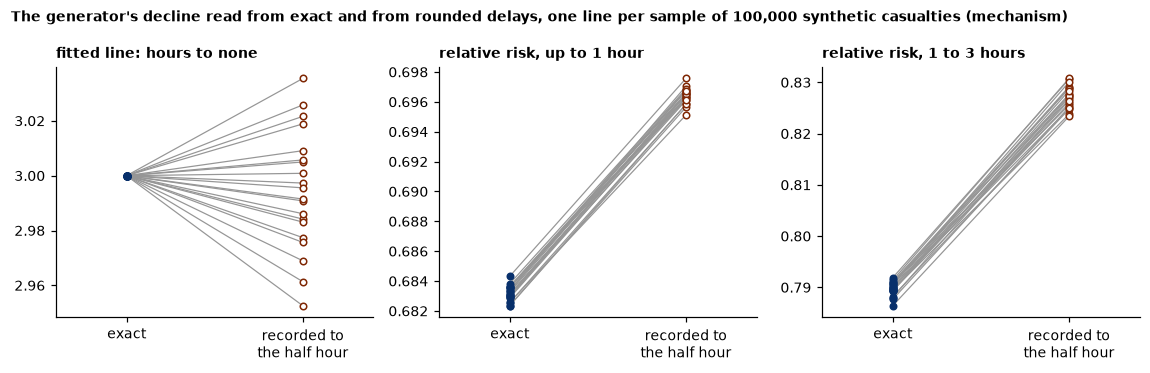

In [16]:
rounding = sto.rounding_summary()
display(rounding)
spread_r = sto.rounding_spread()
one = sto.rounding()
print(f"In the main sample, {one['band changed']:,} of {one['casualties']:,} casualties change band when their delay is "
      f"recorded to the half hour; {one['treated after 3 hours, recorded within']} treated after 3 hours are recorded "
      f"at 180 minutes. Across {len(spread_r)} further samples, from {spread_r['band changed'].min():,} to "
      f"{spread_r['band changed'].max():,} change band.")
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, (key, title) in zip(axes, (("none after, hours", "fitted line: hours to none"),
                                   ("up to 1 hour", "relative risk, up to 1 hour"),
                                   ("1 to 3 hours", "relative risk, 1 to 3 hours"))):
    for seed, row in spread_r.iterrows():
        ax.plot([0, 1], [row[f"{key}, exact"], row[f"{key}, recorded"]], color=GREY, linewidth=0.8)
    ax.scatter(np.zeros(len(spread_r)), spread_r[f"{key}, exact"], s=18, color=MID, zorder=3)
    ax.scatter(np.ones(len(spread_r)), spread_r[f"{key}, recorded"], s=18, color="white", edgecolor=DARK, zorder=3)
    ax.set_xticks([0, 1], ["exact", "recorded to\nthe half hour"])
    ax.set_xlim(-0.4, 1.4)
    ax.set_title(title, loc="left", fontsize=9)
fig.suptitle("The generator's decline read from exact and from rounded delays, one line per sample of 100,000 "
             "synthetic casualties (mechanism)", x=0.01, ha="left", fontweight="bold", fontsize=9)
plt.tight_layout()
plt.show()

Rounding leaves the fitted line where it was: on recorded times it reaches none at the same time, a tie across the 20 samples. The bands move, both towards no effect, on every sample. A casualty treated after 60 and before 75 minutes is recorded at 60 and counted in the first band, so the first band gains casualties with less benefit left than its own, and the second loses those with the most. A few treated after 3 hours, when the drug in the generator does harm, are recorded at 180 minutes and counted in the second band. Each band then reports less benefit than the same band read from exact times, the second by more. A band is a coarse clock, and rounded times make it coarser.

## The failure: a constant hazard fitted to a front-loaded process

The fixed-rate chain is fitted to the same median time to death as the time-varying hazard, so the two agree on when the middle death comes. Now run the generator with its constant-hazard option, used here and nowhere else. Whether each bleeding casualty dies is decided exactly as before; only the time of death changes, drawn at a fixed hourly rate for a casualty who will die. The same synthetic casualties are drawn under each hazard, in 20 samples of 400,000, and among the battle casualties bleeding significantly the hourly death rate among those still alive is measured in the hour around 1, 6, 9 and 12 hours after injury, as the generator's own calibration measures it, without tranexamic acid. E-85's three rates are the yardstick; they were measured from admission and are run here from injury, an assumption.

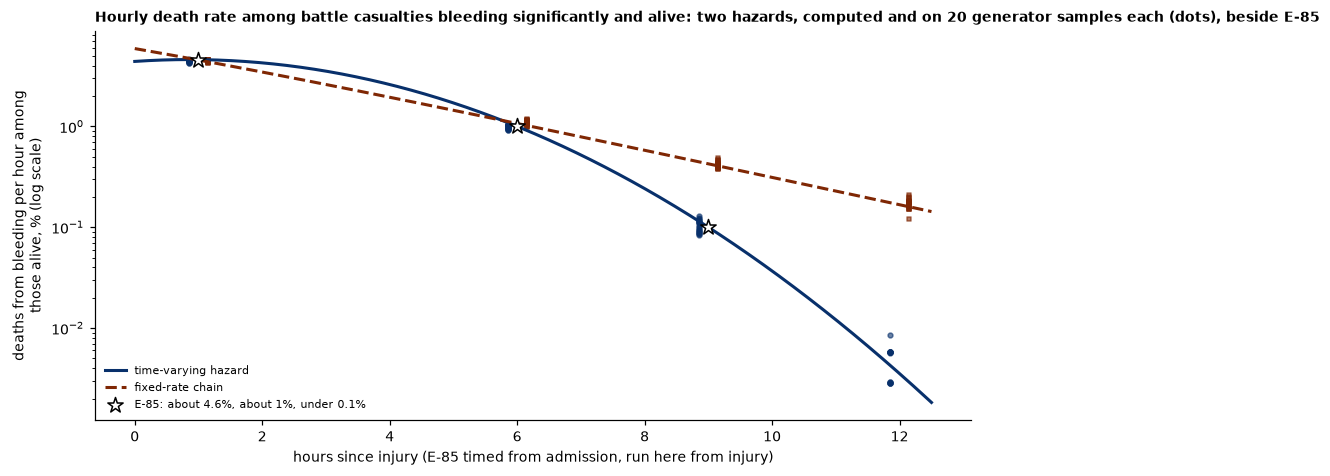

Samples with no death in the hour measured, not drawn on the log scale: 5 under the time-varying hazard, 0 under the fixed-rate chain


,time-varying hazard,fixed-rate chain,fixed-rate less time-varying
"figure, mean over seeds",,,
"rate at 1 hours, %",4.471,4.442,a tie: no detectable difference (the difference runs from -0.101 to +0.063 points across 20 seeds)
"rate at 6 hours, %",0.993,1.085,a tie: no detectable difference (the difference runs from -0.036 to +0.236 points across 20 seeds)
"rate at 9 hours, %",0.104,0.418,higher: the difference runs from +0.267 to +0.372 points across 20 seeds
"rate at 12 hours, %",0.004,0.171,higher: the difference runs from +0.120 to +0.201 points across 20 seeds
"share of deaths after 6 hours, %",6.000,15.300,higher: the difference runs from +8.6 to +9.9 points across 20 seeds


In [17]:
fail = sto.failure_summary()
runs = sto.failure_spread()
fig, ax = plt.subplots(figsize=(9, 4.4))
line = np.linspace(0, 12.5, 751)
ax.semilogy(line, 100 * sto.hourly_rate(line), color=MID, linewidth=2, label="time-varying hazard")
ax.semilogy(line, 100 * sto.hourly_rate(line, "constant"), "--", color=DARK, linewidth=2, label="fixed-rate chain")
for hazard, colour, shift, marker in (("time_varying", MID, -0.15, "o"), ("constant", DARK, 0.15, "s")):
    r = runs[runs["hazard"] == hazard]
    for hour in sto.HOURS + (12.0,):
        values = 100 * r[f"rate at {hour:g} hours"].to_numpy()
        values = values[values > 0]
        ax.scatter(np.full(values.size, hour + shift), values, s=10, color=colour, alpha=0.6, marker=marker)
ax.scatter(sto.HOURS, [100 * float(sto.hourly_rate(h)) for h in sto.HOURS], s=110, marker="*", color="white", edgecolor="black", zorder=4,
           label="E-85: about 4.6%, about 1%, under 0.1%")
ax.set_xlabel("hours since injury (E-85 timed from admission, run here from injury)")
ax.set_ylabel("deaths from bleeding per hour among\nthose alive, % (log scale)")
ax.legend(fontsize=7, frameon=False, loc="lower left")
ax.set_title("Hourly death rate among battle casualties bleeding significantly and alive: two hazards, computed and on "
             "20 generator samples each (dots), beside E-85", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
zero = runs.filter(like="rate at").eq(0).groupby(runs["hazard"]).sum().sum(axis=1)
print(f"Samples with no death in the hour measured, not drawn on the log scale: {int(zero.get('time_varying', 0))} "
      f"under the time-varying hazard, {int(zero.get('constant', 0))} under the fixed-rate chain")
fail

At 1 and 6 hours the two hazards are a tie across the 20 samples, and both sit near E-85's rates. From 9 hours they part: the fixed-rate chain holds the rate at over four times E-85's under 0.1%, and by 12 hours far higher still against the time-varying hazard. For a casualty who will die, the fixed-rate chain is memoryless: one still alive at 9 hours faces the same hourly chance as at the start, and among all those alive the rate falls only as the casualties who will die are used up. E-85 measured a rate that falls much faster.

The consequence is in how long the danger lasts. The cell below gives the time after injury at which the hourly rate among those alive first falls to E-85's 9-hour level, and, for a casualty bleeding significantly and still alive at 6 hours, the chance of dying from bleeding in the next 3 hours, under each description. The fixed-rate chain is not wrong everywhere: on the share of deaths within 6 hours it sat closer to E-85 than the time-varying hazard. Its failure is a shape that does not follow how the risk changes: fitted on one figure, it is wrong on those it was not fitted to.

In [18]:
level = 0.001
for hazard, name in (("time_varying", "time-varying hazard"), ("constant", "fixed-rate chain")):
    print(f"{name}: the hourly rate first falls to {level:.1%} at {sto.rate_falls_to(level, hazard):.1f} hours after "
          f"injury; alive at 6 hours, the chance of dying from bleeding by 9 hours is "
          f"{float(sto.chance_between(6, 9, hazard)):.2%}; at 12 hours the rate is {100 * float(sto.hourly_rate(12, hazard)):.4f}% "
          f"an hour (computed from the hazard; E-85 timed from admission, run from injury)")

time-varying hazard: the hourly rate first falls to 0.1% at 9.0 hours after injury; alive at 6 hours, the chance of dying from bleeding by 9 hours is 1.26%; at 12 hours the rate is 0.0035% an hour (computed from the hazard; E-85 timed from admission, run from injury)
fixed-rate chain: the hourly rate first falls to 0.1% at 13.7 hours after injury; alive at 6 hours, the chance of dying from bleeding by 9 hours is 2.08%; at 12 hours the rate is 0.1673% an hour (computed from the hazard; E-85 timed from admission, run from injury)


## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label; axes 3, 4 and 5 are stated; axis 7 is net benefit at a threshold of 0.10 for every lens (D-26).

The diagnosis column is the lens's chance of dying from bleeding in the next hour, scored on the battle casualties among the 100,000 synthetic casualties (seed 42) who are bleeding significantly and alive at pre-hospital care, against death from bleeding within the hour after it, without tranexamic acid. Fit is weak: the lens describes the clock, not who is bleeding, and is told who is. The baseline is the MPTT-24 read as its figure was published, with the text reading beside it, labelled as validated (D-24), scored against the same target, which the rule was not written for. Among the generator's injured in the military cohort, battle and non-battle injury together, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The treatment column is the expected deaths from bleeding averted by tranexamic acid at each casualty's own delay; fit is native. The rule states no treatment effect, so the treatment rows hold no baseline figure (NaN). Spreads are across 20 further samples.

In [19]:
sto.seven_axes()

,diagnosis: chance of death from bleeding in the next hour,"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)",treatment: benefit of tranexamic acid left at the delay
axis,,,,
1 Discrimination (mechanism),"It flags none at the threshold of 0.10: the highest chance among them is 0.0448, below the threshold of 0.1000, so sensitivity 0.0%, specificity 100.0%; 10,352 synthetic battle casualties bleeding significantly and alive at pre-hospital care, of whom 439 die from bleeding within the hour","sensitivity 62.0%, specificity 38.3%, against death within the hour, which the rule was not written for. Among the generator's injured in the military cohort, battle and non-battle injury together, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23)","sensitivity 62.4%, specificity 37.9%","Not a classifier: expected deaths from bleeding averted per 100 battle casualties bleeding significantly and alive at pre-hospital care, with the drug at their own delay, 4.14 (2.44 to 5.65); with every one of them reached 30 minutes later, 2.64 (1.53 to 3.61); 30 minutes later less their own delay, across 20 further samples, lower: the difference runs from -1.51 to -1.50 per 100 across 20 seeds; the generator's own count on the same casualties at their own delay, 4.15"
2 Calibration (mechanism),"Brier 0.0406; mean chance minus observed share +0.0006. The lens's hazard is the generator's, so this holds by construction. The lens's Brier score less the rule's, across 20 further samples: lower: the difference runs from -0.573 to -0.558 across 20 seeds","Brier 0.607; it flags 57.4 points more than die within the hour. A rule gives no probability, so the Brier score is the share misclassified","Brier 0.611; it flags 57.9 points more than die within the hour. A rule gives no probability, so the Brier score is the share misclassified","The lens's expected deaths averted less the generator's count: -0.02 per 100; across 20 further samples, a tie: no detectable difference (the difference runs from -0.42 to +0.40 per 100 across 20 seeds). The lens's line and the generator were both set from E-22 (CRASH-2, a civilian trial), so agreement is by construction"
3 Uncertainty expressed,None: one chance for each casualty,None: a priority,None: a priority,"A distribution: E-22's bands carried as 4,000 draws"
4 What it needed,"A hazard through three published hourly rates (E-85: 4,064 haemorrhaging patients in five prospective studies at civilian centres, timed from hospital admission, run here from injury, an assumption), the time since injury, and who is bleeding significantly, which the generator supplies and no medic knows for certain",Rules only (E-08),Rules only (E-08),"E-22's bands, from an exploratory analysis (E-23) of CRASH-2, a civilian trial; E-24's end of the benefit at about 3 hours, from pooled trials half of whose patients were obstetric (E-26); a straight line and the generator's spread of delays within the first band (assumptions)"
5 Readability,One look-up: minutes since injury to a chance,Six yes-or-no steps,Six yes-or-no steps,One line: the benefit falls to none at 3 hours
"6 Robustness, setting changed (mechanism)","Scan in hospital: sensitivity 0.0%, specificity 100.0%, Brier 0.0406, unchanged because in the generator the setting changes only the scan, which this lens does not read","Scan in hospital: sensitivity 62.0%, specificity 38.3%, unchanged","Scan in hospital: sensitivity 62.4%, specificity 37.9%, unchanged",Unchanged: the delay does not depend on where the scan is done
7 Decision value,"Net benefit 0.0 per 100 at a threshold of 0.10 (it flags no casualty at this threshold, so it scores exactly as treating none), with a miss weighed 9 times a false alarm (an assumption); treat all -6.4 (worse than treating none), treat none 0 (mechanism). Across 20 further samples the l

In [20]:
card = pd.DataFrame([vars(row) for row in sto.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity at 0.10, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan before hospital",0.000e+00,0.620,mechanism,weak,generator
1,diagnosis,"specificity at 0.10, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan before hospital",1.000e+00,0.383,mechanism,weak,generator
2,diagnosis,"Brier score, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan before hospital",4.060e-02,0.607,mechanism,weak,generator
3,diagnosis,"mean chance minus observed share, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan before hospital",6.000e-04,0.574,mechanism,weak,generator
4,diagnosis,"sensitivity at 0.10, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan in hospital",0.000e+00,0.620,mechanism,weak,generator
5,diagnosis,"specificity at 0.10, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan in hospital",1.000e+00,0.383,mechanism,weak,generator
6,diagnosis,"Brier score, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan in hospital",4.060e-02,0.607,mechanism,weak,generator
7,diagnosis,"mean chance minus observed share, chance of dying from bleeding in the next hour against death from bleeding within the hour after pre-hospital care, battle casualties bleeding significantly and alive at pre-hospital care, scan in hospital",6.000e-04,0.574,mechanism,weak,generator
8,treatment,"expected deaths from bleeding averted per 100 by tranexamic acid at each casualty's own delay, lens's decline, mean of 4,000 draws, battle casualties bleeding significantly and alive at pre-hospital care",4.137e+00,NaN,mechanism,native,generator
9,treatment,"lens's expected deaths averted per 100 less the generator's own count, battle casualties bleeding significantly and alive at pre-hospital care",-1.640e-02,NaN,mechanism,native,generator


Two rows carry the lesson.

**Diagnosis.** The lens's chance matches the share who die within the hour because its hazard is the generator's, and it flags no casualty at 0.10, so its net benefit is that of treating none. The rule flags more than half of them and does worse than treating none at that threshold, on every one of 20 samples. Neither separates those who die within the hour from those who do not: the lens's chance varies little from one casualty to the next, and the rule's sensitivity and specificity add to about one (mechanism).

**Treatment.** On the generator, the drug at each casualty's own delay averts about 4 deaths from bleeding per 100 casualties bleeding significantly and alive at pre-hospital care, and reaching every one of them 30 minutes later would avert fewer on every one of 20 samples. The figures rest on E-22's exploratory bands from a civilian trial and on an assumed straight line; they describe the generator, not a battlefield.

**Teach back.** In one sentence, why can a model be right about a thousand casualties and still say little about the one in front of you?

## The brain analogy, and where it breaks

**What it resembles.** Neural noise and sampling. Neurons fire irregularly, and the same stimulus never produces quite the same response twice. One way of thinking about that variability, offered here as an analogy and not as a finding, is as a description of uncertainty in bulk, as a stochastic model describes the crowd rather than the individual.

**Where it breaks.** The resemblance is suggestive only. A hazard fitted to hourly death rates says nothing about neurons, and the irregular firing of neurons is not evidence that the brain computes with chains or hazards. The analogy is a way to remember that the dice can be described when the roll cannot, not a claim about how the brain works.